# Reaction-time inference and presentation results

This notebook loads the authoritative mouse-level summary exported by `reaction_time_analysis.ipynb`, performs robust inference, and creates the final presentation figures and tables.

**Question:** Are prior-congruent choices initiated faster than prior-incongruent choices when visual evidence is absent or weak?

All analyses use valid completed choices, with the mouse as the independent unit (139 mice, 459 sessions). Positive paired differences mean slower prior-incongruent movement initiation.


## 1. Configuration

In [1]:
from pathlib import Path
import os
import tempfile


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "reaction_time_trials.parquet").exists():
            return candidate
    raise FileNotFoundError("Could not locate data/reaction_time_trials.parquet")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "rt-matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

DATA_PATH = PROJECT_ROOT / "data" / "reaction_time_trials.parquet"
MOUSE_SUMMARY_PATH = PROJECT_ROOT / "results" / "analysis" / "tables" / "mouse_summary.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "inference"
FIGURE_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CONTRASTS = [0.0, 0.0625, 0.125]
CONTRAST_LABELS = ["0%", "6.25%", "12.5%"]
CONTRAST_LABEL_MAP = dict(zip(CONTRASTS, CONTRAST_LABELS))
SEED = 2026
N_BOOTSTRAP = 20_000
ALPHA = 0.05

# Color-blind-friendly, slide-safe palette.
COLORS = {
    "congruent": "#2F6BBD",
    "incongruent": "#2EAD67",
    "effect": "#6D4CC2",
    "positive": "#16856B",
    "negative": "#B34D5A",
    "ink": "#17212B",
    "muted": "#5D6975",
    "grid": "#DCE2E8",
    "paper": "#FFFFFF",
}

plt.rcParams.update({
    "figure.facecolor": COLORS["paper"],
    "axes.facecolor": COLORS["paper"],
    "savefig.facecolor": COLORS["paper"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 19,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 13,
    "axes.edgecolor": COLORS["ink"],
    "axes.labelcolor": COLORS["ink"],
    "xtick.color": COLORS["ink"],
    "ytick.color": COLORS["ink"],
    "text.color": COLORS["ink"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.hashsalt": "prior-choice-reaction-time",
})


def save_figure(fig, stem: str) -> None:
    fig.savefig(
        FIGURE_DIR / f"{stem}.png",
        dpi=240,
        bbox_inches="tight",
        metadata={"Software": "Matplotlib"},
    )
    svg_path = FIGURE_DIR / f"{stem}.svg"
    fig.savefig(
        svg_path,
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib", "Date": None},
    )
    svg_text = svg_path.read_text(encoding="utf-8")
    svg_path.write_text(
        "".join(f"{line.rstrip()}\n" for line in svg_text.splitlines()),
        encoding="utf-8",
    )


print("Configuration ready; loading committed analysis summaries.")


Configuration ready; loading committed analysis summaries.


## 2. Reconstruct mouse-level effects and run inference

Within each session and condition, RT is summarized by the median. The paired session difference is incongruent minus congruent. Session differences are averaged within mouse, and the cohort effect is the median across mice.

Confidence intervals resample whole mice. Directional consistency is tested with two-sided exact sign tests and Holm correction across the three contrasts.

In [2]:
trials = pd.read_parquet(DATA_PATH)
assert len(trials) == 89_931
assert trials["eid"].nunique() == 459
assert trials["subject"].nunique() == 139
assert int(trials["valid_rt"].sum()) == 89_871

if not MOUSE_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Run reaction_time_analysis.ipynb first to create results/analysis/tables/mouse_summary.csv"
    )

mouse_summary = pd.read_csv(MOUSE_SUMMARY_PATH)
required_columns = {
    "subject", "contrast", "contrast_label", "n_sessions",
    "congruent_rt_ms", "incongruent_rt_ms", "difference_ms",
}
assert required_columns.issubset(mouse_summary.columns)
assert len(mouse_summary) == 139 * 3
assert mouse_summary["subject"].nunique() == 139
assert mouse_summary.groupby("contrast", observed=True)["subject"].nunique().eq(139).all()
assert np.allclose(
    mouse_summary["difference_ms"],
    mouse_summary["incongruent_rt_ms"] - mouse_summary["congruent_rt_ms"],
)

def holm_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    order = np.argsort(values)
    ordered = values[order]
    adjusted_ordered = np.maximum.accumulate(ordered * (len(values) - np.arange(len(values))))
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = np.clip(adjusted_ordered, 0, 1)
    return adjusted


def bootstrap_median_interval(values, rng, n_resamples=N_BOOTSTRAP):
    values = np.asarray(values, dtype=float)
    indices = rng.integers(0, len(values), size=(n_resamples, len(values)))
    bootstrap_medians = np.median(values[indices], axis=1)
    return np.quantile(bootstrap_medians, [0.025, 0.975])


rng = np.random.default_rng(SEED)
inference_rows = []
for contrast, label in zip(CONTRASTS, CONTRAST_LABELS):
    values = mouse_summary.loc[
        np.isclose(mouse_summary["contrast"], contrast), "difference_ms"
    ].to_numpy()
    positive = int(np.sum(values > 0))
    negative = int(np.sum(values < 0))
    zero = int(np.sum(values == 0))
    ci_low, ci_high = bootstrap_median_interval(values, rng)
    sign_p = stats.binomtest(
        positive, n=positive + negative, p=0.5, alternative="two-sided"
    ).pvalue
    inference_rows.append({
        "contrast": label,
        "n_mice": len(values),
        "n_positive": positive,
        "n_negative": negative,
        "n_zero": zero,
        "median_difference_ms": float(np.median(values)),
        "mean_difference_ms": float(np.mean(values)),
        "ci95_low_ms": float(ci_low),
        "ci95_high_ms": float(ci_high),
        "sign_p_raw": float(sign_p),
    })

inference = pd.DataFrame(inference_rows)
inference["sign_p_holm"] = holm_adjust(inference["sign_p_raw"])
inference["reject_holm_0_05"] = inference["sign_p_holm"] < ALPHA
inference["percent_positive"] = 100 * inference["n_positive"] / inference["n_mice"]
inference["contrast"] = pd.Categorical(
    inference["contrast"], categories=CONTRAST_LABELS, ordered=True
)
inference = inference.sort_values("contrast").reset_index(drop=True)

paired = (
    mouse_summary.pivot(index="subject", columns="contrast_label", values="difference_ms")
    .reindex(columns=CONTRAST_LABELS)
    .sort_index()
)
friedman = stats.friedmanchisquare(*(paired[label] for label in CONTRAST_LABELS))
contrast_effect_tests = pd.DataFrame([{
    "test": "Friedman omnibus",
    "comparison": "0% vs 6.25% vs 12.5%",
    "n_mice": len(paired),
    "statistic": float(friedman.statistic),
    "p_raw": float(friedman.pvalue),
    "reject_0_05": bool(friedman.pvalue < ALPHA),
}])
contrast_test = contrast_effect_tests.iloc[0]

assert inference["n_positive"].tolist() == [95, 103, 111]
assert np.allclose(
    inference["median_difference_ms"],
    [20.112557884414986, 18.677853315011816, 13.976271688079578],
)
assert np.isclose(contrast_test["p_raw"], 0.4309657671042948)

inference.to_csv(TABLE_DIR / "primary_inference.csv", index=False)
contrast_effect_tests.to_csv(TABLE_DIR / "contrast_effect_tests.csv", index=False)

result_table = inference[[
    "contrast", "n_mice", "median_difference_ms", "ci95_low_ms", "ci95_high_ms",
    "n_positive", "percent_positive", "sign_p_holm",
]].copy()
result_table.columns = [
    "Contrast", "Mice", "Median I−C (ms)", "CI low", "CI high",
    "Positive mice", "Positive (%)", "Holm-adjusted p",
]
display(result_table.style.format({
    "Median I−C (ms)": "{:+.1f}",
    "CI low": "{:+.1f}",
    "CI high": "{:+.1f}",
    "Positive (%)": "{:.1f}",
    "Holm-adjusted p": "{:.2e}",
}))
display(contrast_effect_tests)


,Contrast,Mice,Median I−C (ms),CI low,CI high,Positive mice,Positive (%),Holm-adjusted p
0,0%,139,+20.1,+12.3,+26.1,95,68.3,1.82e-05
1,6.25%,139,+18.7,+12.1,+23.1,103,74.1,2.27e-08
2,12.5%,139,+14.0,+10.8,+19.5,111,79.9,2.04e-12


,test,comparison,n_mice,statistic,p_raw,reject_0_05
0,Friedman omnibus,0% vs 6.25% vs 12.5%,139,1.683453,0.430966,False


## Figure 1 — Detailed paired mouse view

This is a presentation-optimized version of the original six-panel figure. It retains all 139 mouse-level observations and the full data range, but uses larger typography, higher-contrast marks, clearer axis labels, and a 16:9 slide layout.

The upper row shows paired congruent and incongruent RT values for every mouse. The lower row shows the direct paired difference for every mouse. Use this as the opening descriptive results slide; Figure 2 provides the formal effect estimates and uncertainty.


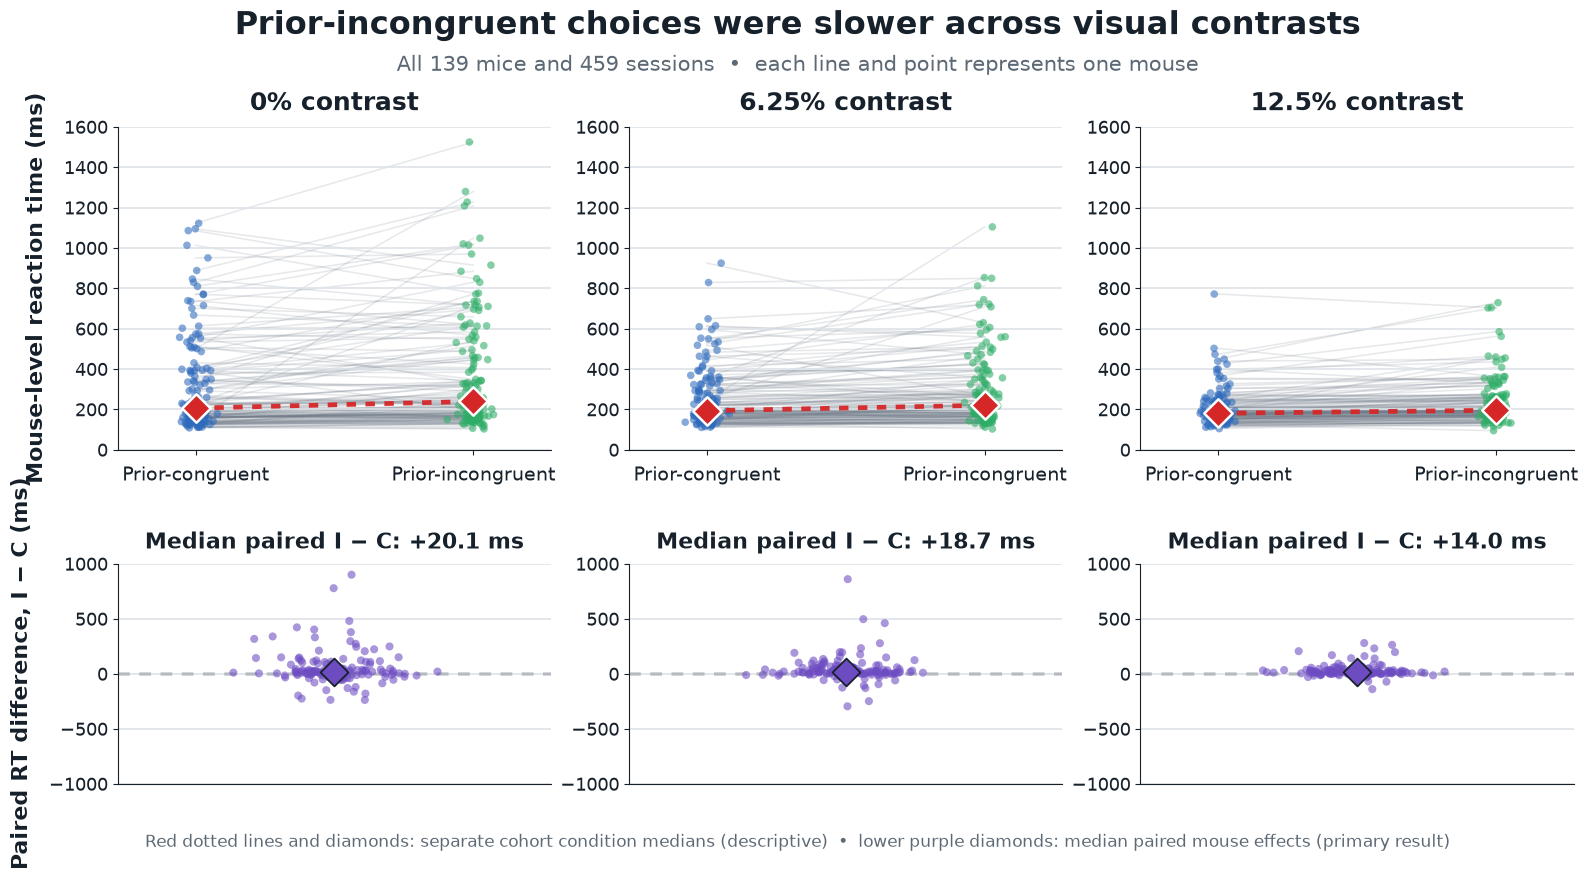

In [3]:
# Presentation version of the original all-mice paired graph.
rng = np.random.default_rng(SEED)
MEDIAN_HIGHLIGHT = "#D62728"

condition_max = mouse_summary[["congruent_rt_ms", "incongruent_rt_ms"]].to_numpy().max()
condition_ymax = max(600, int(np.ceil(condition_max / 200) * 200))
difference_max = np.abs(mouse_summary["difference_ms"]).max()
difference_limit = max(500, int(np.ceil(difference_max / 250) * 250))


fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    sharey="row",
    gridspec_kw={"height_ratios": [1.35, 0.92]},
)

for column, (contrast, label) in enumerate(zip(CONTRASTS, CONTRAST_LABELS)):
    current = (
        mouse_summary.loc[np.isclose(mouse_summary["contrast"], contrast)]
        .sort_values("subject")
        .reset_index(drop=True)
    )
    infer = inference.loc[inference["contrast"].astype(str).eq(label)].iloc[0]

    # Upper panel: paired condition RTs.
    top = axes[0, column]
    for row in current.itertuples():
        top.plot(
            [0, 1], [row.congruent_rt_ms, row.incongruent_rt_ms],
            color="#687482", alpha=0.16, linewidth=1.15, zorder=1,
        )

    jitter_c = rng.normal(0, 0.025, len(current))
    jitter_i = rng.normal(0, 0.025, len(current))
    top.scatter(
        jitter_c, current["congruent_rt_ms"],
        s=30, color=COLORS["congruent"], alpha=0.58,
        edgecolors="none", zorder=2,
    )
    top.scatter(
        1 + jitter_i, current["incongruent_rt_ms"],
        s=30, color=COLORS["incongruent"], alpha=0.58,
        edgecolors="none", zorder=2,
    )

    condition_medians = [
        current["congruent_rt_ms"].median(),
        current["incongruent_rt_ms"].median(),
    ]
    top.plot(
        [0, 1], condition_medians,
        color=MEDIAN_HIGHLIGHT, linewidth=3.4, linestyle=(0, (2, 2)), alpha=0.95, zorder=3,
    )
    top.scatter(
        [0, 1], condition_medians,
        s=210, marker="D", color=MEDIAN_HIGHLIGHT,
        edgecolor=COLORS["paper"], linewidth=1.8, zorder=4,
    )
    top.set_title(f"{label} contrast", fontsize=18, weight="bold", pad=12)
    top.set_xticks([0, 1], ["Prior-congruent", "Prior-incongruent"])
    top.set_xlim(-0.28, 1.28)
    top.set_ylim(0, condition_ymax)
    top.tick_params(axis="x", labelsize=14, pad=8)
    top.tick_params(axis="y", labelsize=13)
    top.grid(axis="y", color=COLORS["grid"], linewidth=1.15)
    if column == 0:
        top.set_ylabel("Mouse-level reaction time (ms)", fontsize=16, weight="bold", labelpad=12)

    # Lower panel: direct mouse-level paired differences.
    bottom = axes[1, column]
    jitter = rng.normal(0, 0.045, len(current))
    bottom.axhline(
        0, color=COLORS["ink"], linestyle=(0, (5, 4)), linewidth=1.7, zorder=1,
    )
    bottom.scatter(
        jitter, current["difference_ms"],
        s=34, color=COLORS["effect"], alpha=0.58,
        edgecolors="none", zorder=2,
    )
    bottom.scatter(
        [0], [infer["median_difference_ms"]],
        s=200, marker="D", color=COLORS["effect"],
        edgecolor=COLORS["ink"], linewidth=1.3, zorder=4,
    )
    bottom.set_title(
        f"Median paired I − C: {infer['median_difference_ms']:+.1f} ms",
        fontsize=16, weight="bold", pad=11,
    )
    bottom.set_xlim(-0.28, 0.28)
    bottom.set_ylim(-difference_limit, difference_limit)
    bottom.set_xticks([])
    bottom.tick_params(axis="y", labelsize=13)
    bottom.grid(axis="y", color=COLORS["grid"], linewidth=1.15)
    if column == 0:
        bottom.set_ylabel("Paired RT difference, I − C (ms)", fontsize=16, weight="bold", labelpad=12)

# Keep numeric y tick labels visible in all columns despite shared axes.
for axis in [*axes[0, :], *axes[1, :]]:
    axis.tick_params(labelleft=True)

fig.text(
    0.5, 0.965,
    "Prior-incongruent choices were slower across visual contrasts",
    ha="center", va="top", fontsize=23, weight="bold",
)
fig.text(
    0.5, 0.915,
    "All 139 mice and 459 sessions  •  each line and point represents one mouse",
    ha="center", va="top", fontsize=15, color=COLORS["muted"],
)
fig.text(
    0.5, 0.035,
    "Red dotted lines and diamonds: separate cohort condition medians (descriptive)  •  "
    "lower purple diamonds: median paired mouse effects (primary result)",
    ha="center", fontsize=12.5, color=COLORS["muted"],
)
fig.subplots_adjust(
    left=0.075, right=0.985, top=0.835, bottom=0.105,
    wspace=0.18, hspace=0.42,
)

save_figure(fig, "01_detailed_paired_mouse_results")
plt.show()


## Figure 2 — Primary result

This is the recommended main results slide. The zero line represents no congruency-associated RT difference; points to the right indicate slower prior-incongruent choices.


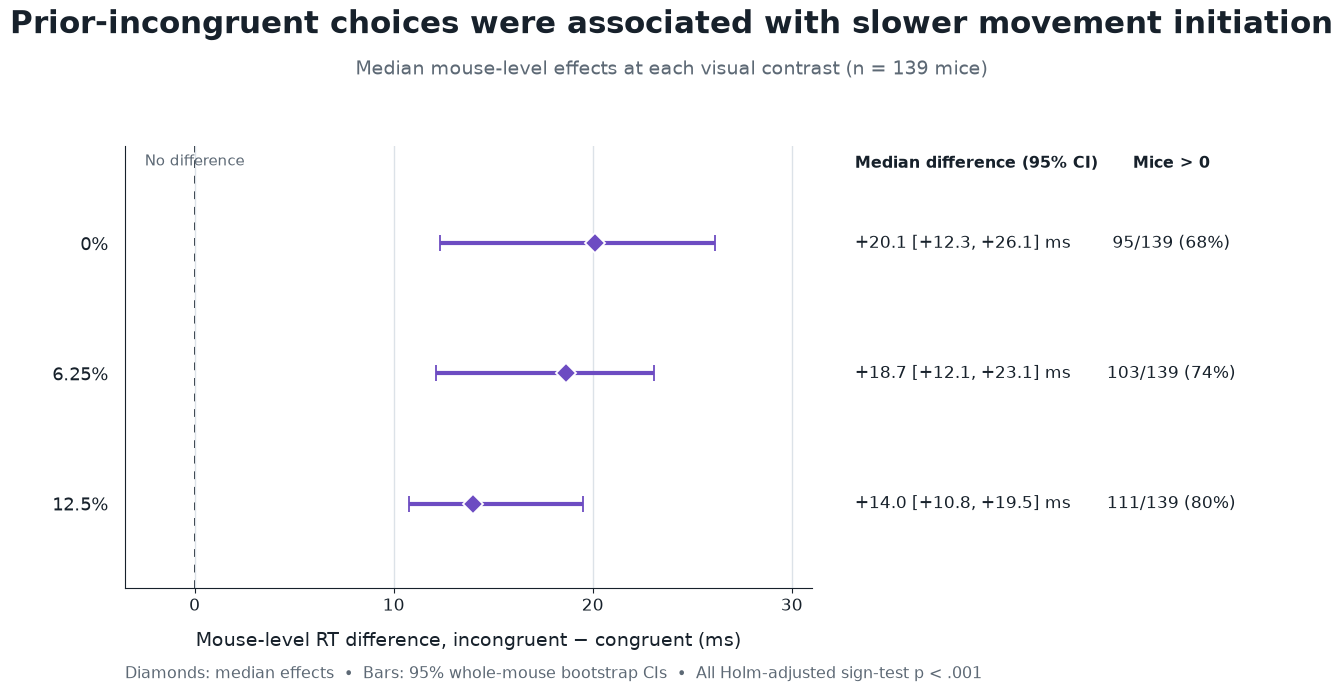

In [4]:
rows = inference.iloc[::-1].reset_index(drop=True)
y = np.arange(len(rows))
estimate = rows["median_difference_ms"].to_numpy()
low = rows["ci95_low_ms"].to_numpy()
high = rows["ci95_high_ms"].to_numpy()

fig = plt.figure(figsize=(13.33, 7.5))
grid = fig.add_gridspec(
    1, 2, width_ratios=[2.05, 1.35],
    left=0.09, right=0.97, top=0.79, bottom=0.20, wspace=0.06,
)
ax = fig.add_subplot(grid[0, 0])
table_ax = fig.add_subplot(grid[0, 1], sharey=ax)

ax.axvline(0, color=COLORS["ink"], linewidth=1.4, linestyle=(0, (4, 4)), zorder=1)
ax.errorbar(
    estimate, y,
    xerr=np.vstack([estimate - low, high - estimate]),
    fmt="D", markersize=10, color=COLORS["effect"], ecolor=COLORS["effect"],
    elinewidth=3, capsize=6, capthick=2.2, markeredgecolor=COLORS["paper"],
    markeredgewidth=1.3, zorder=3,
)

ax.set_yticks(y, rows["contrast"].astype(str))
ax.set_xlabel("Mouse-level RT difference, incongruent − congruent (ms)", labelpad=12)
ax.set_xlim(-3.5, 31)
ax.set_xticks([0, 10, 20, 30])
ax.set_ylim(-0.65, 2.75)
ax.grid(axis="x", color=COLORS["grid"], linewidth=1)
ax.tick_params(axis="y", length=0, pad=12)
ax.text(0, 2.57, "No difference", ha="center", va="bottom", color=COLORS["muted"], fontsize=11)

table_ax.set_xlim(0, 1)
table_ax.set_ylim(ax.get_ylim())
table_ax.axis("off")
table_ax.text(0.02, 2.58, "Median difference (95% CI)", fontsize=11.5, weight="bold")
table_ax.text(0.72, 2.58, "Mice > 0", fontsize=11.5, weight="bold", ha="center")
for yi, row in zip(y, rows.to_dict("records")):
    effect_text = (
        f"{row['median_difference_ms']:+.1f} "
        f"[{row['ci95_low_ms']:+.1f}, {row['ci95_high_ms']:+.1f}] ms"
    )
    positive_text = f"{row['n_positive']}/{row['n_mice']} ({row['percent_positive']:.0f}%)"
    table_ax.text(0.02, yi, effect_text, va="center", fontsize=12.5)
    table_ax.text(0.72, yi, positive_text, va="center", ha="center", fontsize=12.5)

fig.text(
    0.5, 0.94,
    "Prior-incongruent choices were associated with slower movement initiation",
    ha="center", fontsize=22, weight="bold",
)
fig.text(
    0.5, 0.885,
    "Median mouse-level effects at each visual contrast (n = 139 mice)",
    ha="center", fontsize=14, color=COLORS["muted"],
)
fig.text(
    0.09, 0.08,
    "Diamonds: median effects  •  Bars: 95% whole-mouse bootstrap CIs  •  "
    "All Holm-adjusted sign-test p < .001",
    fontsize=11.5, color=COLORS["muted"],
)

save_figure(fig, "02_primary_effect_forest")
plt.show()


## Figure 3 — Reaction-time profile

This figure gives an intuitive view of the underlying condition medians. It is useful immediately before or after the primary effect plot.


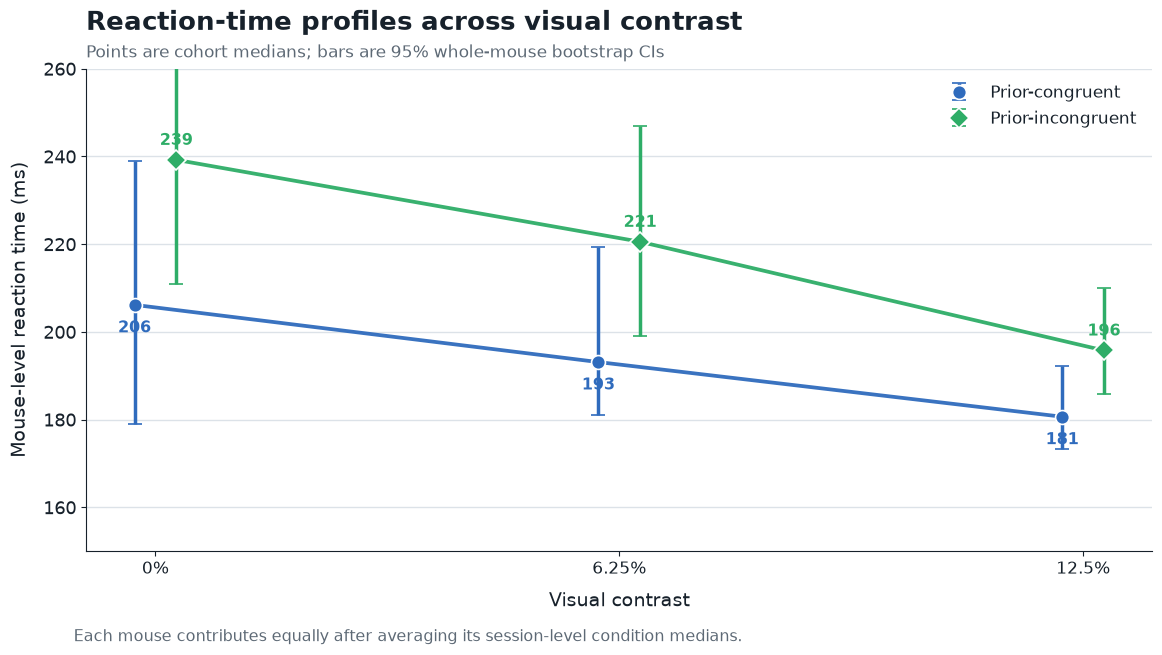

In [5]:
profile_rows = []
for contrast, label in zip(CONTRASTS, CONTRAST_LABELS):
    current = mouse_summary.loc[np.isclose(mouse_summary["contrast"], contrast)]
    for condition_name, column in [
        ("Prior-congruent", "congruent_rt_ms"),
        ("Prior-incongruent", "incongruent_rt_ms"),
    ]:
        values = current[column].to_numpy()
        ci_low, ci_high = bootstrap_median_interval(
            values, np.random.default_rng(SEED + len(profile_rows))
        )
        profile_rows.append({
            "contrast": label,
            "condition": condition_name,
            "median_rt_ms": np.median(values),
            "ci_low_ms": ci_low,
            "ci_high_ms": ci_high,
        })

profile = pd.DataFrame(profile_rows)
x = np.arange(3)

fig, ax = plt.subplots(figsize=(12.4, 7.2))
for condition_name, color, marker, offset in [
    ("Prior-congruent", COLORS["congruent"], "o", -0.045),
    ("Prior-incongruent", COLORS["incongruent"], "D", 0.045),
]:
    current = profile.loc[profile["condition"].eq(condition_name)].reset_index(drop=True)
    median = current["median_rt_ms"].to_numpy()
    low = current["ci_low_ms"].to_numpy()
    high = current["ci_high_ms"].to_numpy()
    ax.plot(x + offset, median, color=color, linewidth=2.7, alpha=0.95, zorder=2)
    ax.errorbar(
        x + offset, median,
        yerr=np.vstack([median - low, high - median]),
        fmt=marker, markersize=10, color=color, ecolor=color,
        elinewidth=2.5, capsize=5, markeredgecolor=COLORS["paper"],
        markeredgewidth=1.2, label=condition_name, zorder=3,
    )
    for xi, value in zip(x + offset, median):
        dy = 8 if condition_name == "Prior-incongruent" else -11
        ax.annotate(
            f"{value:.0f}", (xi, value), xytext=(0, dy), textcoords="offset points",
            ha="center", va="bottom" if dy > 0 else "top", color=color,
            fontsize=11.5, weight="bold",
        )

ax.set_xticks(x, CONTRAST_LABELS)
ax.set_xlabel("Visual contrast", labelpad=10)
ax.set_ylabel("Mouse-level reaction time (ms)", labelpad=10)
ax.set_ylim(150, 260)
ax.grid(axis="y", color=COLORS["grid"], linewidth=1)
ax.legend(frameon=False, loc="upper right", fontsize=12.5)
ax.set_title(
    "Reaction-time profiles across visual contrast",
    loc="left", pad=28, weight="bold",
)
ax.text(
    0, 1.015,
    "Points are cohort medians; bars are 95% whole-mouse bootstrap CIs",
    transform=ax.transAxes, fontsize=12.5, color=COLORS["muted"], va="bottom",
)
fig.text(
    0.09, 0.035,
    "Each mouse contributes equally after averaging its session-level condition medians.",
    fontsize=11.5, color=COLORS["muted"],
)
fig.subplots_adjust(left=0.10, right=0.96, top=0.83, bottom=0.16)

save_figure(fig, "03_reaction_time_profile")
plt.show()


## Figure 4 — Cohort consistency

This converts the sign-test result into an audience-friendly quantity: the percentage of mice whose RT difference was positive. The intervals are Wilson 95% binomial intervals.


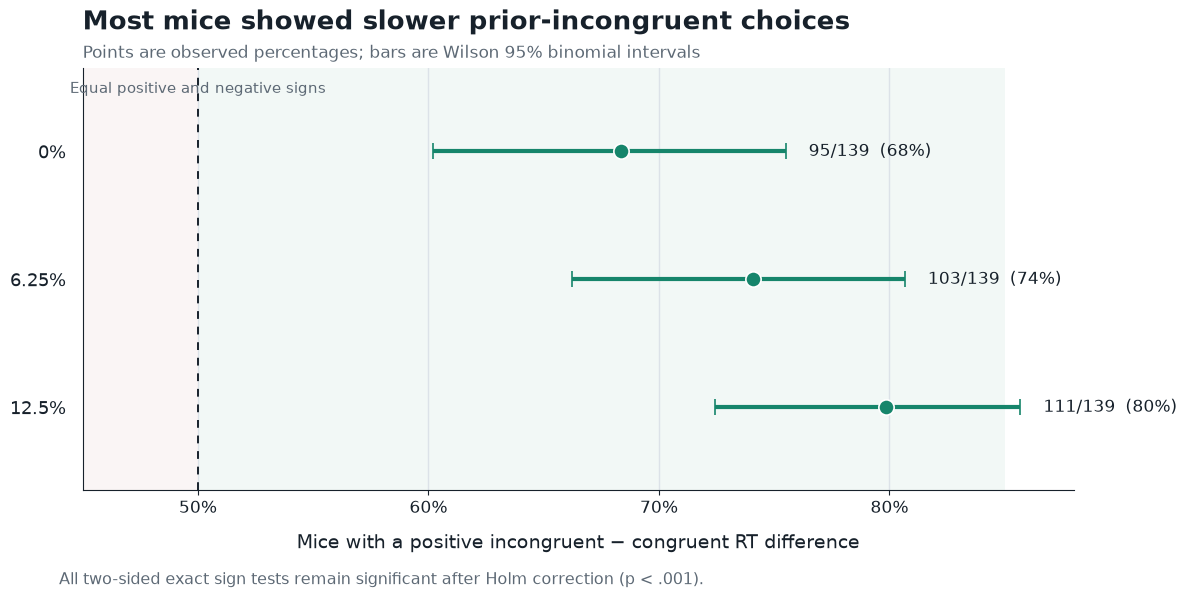

In [6]:
def wilson_interval(successes, total, z=1.959963984540054):
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - half_width, center + half_width


consistency = inference.copy()
wilson = np.array([
    wilson_interval(row.n_positive, row.n_mice)
    for row in consistency.itertuples()
]) * 100
consistency["wilson_low"] = wilson[:, 0]
consistency["wilson_high"] = wilson[:, 1]
consistency = consistency.iloc[::-1].reset_index(drop=True)

y = np.arange(3)
percent = consistency["percent_positive"].to_numpy()
low = consistency["wilson_low"].to_numpy()
high = consistency["wilson_high"].to_numpy()

fig, ax = plt.subplots(figsize=(11.8, 6.7))
ax.axvspan(45, 50, color=COLORS["negative"], alpha=0.055, lw=0)
ax.axvspan(50, 85, color=COLORS["positive"], alpha=0.055, lw=0)
ax.axvline(50, color=COLORS["ink"], linewidth=1.4, linestyle=(0, (4, 4)))
ax.errorbar(
    percent, y,
    xerr=np.vstack([percent - low, high - percent]),
    fmt="o", markersize=11, color=COLORS["positive"], ecolor=COLORS["positive"],
    elinewidth=3, capsize=6, capthick=2.2,
    markeredgecolor=COLORS["paper"], markeredgewidth=1.2, zorder=3,
)

for yi, row in zip(y, consistency.to_dict("records")):
    ax.text(
        row["wilson_high"] + 1.0, yi,
        f"{row['n_positive']}/{row['n_mice']}  ({row['percent_positive']:.0f}%)",
        va="center", fontsize=12.5,
    )

ax.set_yticks(y, consistency["contrast"].astype(str))
ax.set_xlim(45, 88)
ax.set_ylim(-0.65, 2.65)
ax.set_xticks([50, 60, 70, 80], ["50%", "60%", "70%", "80%"])
ax.set_xlabel("Mice with a positive incongruent − congruent RT difference", labelpad=12)
ax.tick_params(axis="y", length=0, pad=12)
ax.grid(axis="x", color=COLORS["grid"], linewidth=1)
ax.set_title(
    "Most mice showed slower prior-incongruent choices",
    loc="left", pad=28, weight="bold",
)
ax.text(
    0, 1.015,
    "Points are observed percentages; bars are Wilson 95% binomial intervals",
    transform=ax.transAxes, fontsize=12.5, color=COLORS["muted"], va="bottom",
)
ax.text(
    50, 2.43, "Equal positive and negative signs", ha="center", va="bottom",
    fontsize=10.5, color=COLORS["muted"],
)
fig.text(
    0.10, 0.04,
    "All two-sided exact sign tests remain significant after Holm correction (p < .001).",
    fontsize=11.5, color=COLORS["muted"],
)
fig.subplots_adjust(left=0.12, right=0.96, top=0.81, bottom=0.18)

save_figure(fig, "04_mouse_level_consistency")
plt.show()


## Reporting guidance

Suggested one-sentence result:

> Across 139 mice, prior-incongruent choices were associated with slower movement initiation at 0%, 6.25%, and 12.5% contrast, with median paired delays of 20.1, 18.7, and 14.0 ms, respectively; all whole-mouse bootstrap 95% CIs excluded zero.

In the detailed paired figure, each grey line connects the two condition summaries from the same mouse. The red diamonds are the separate cohort medians for the congruent and incongruent conditions; their vertical difference is descriptive and is not generally equal to the median of the paired mouse differences. The lower purple diamond is the primary paired estimate.

Do **not** describe the numerical sequence (20.1 → 18.7 → 14.0 ms) as a contrast-dependent decrease. The repeated-measures Friedman test did not find evidence that effect magnitude differed across the three contrasts (`p = 0.431`). The result is associative rather than causal.


## Export and reproducibility checks

In [7]:
expected_stems = [
    "01_detailed_paired_mouse_results",
    "02_primary_effect_forest",
    "03_reaction_time_profile",
    "04_mouse_level_consistency",
]
expected_files = [
    FIGURE_DIR / f"{stem}.{extension}"
    for stem in expected_stems
    for extension in ["png", "svg"]
]
expected_files += [
    TABLE_DIR / "primary_inference.csv",
    TABLE_DIR / "contrast_effect_tests.csv",
]
for path in expected_files:
    assert path.exists() and path.stat().st_size > 0, f"Missing output: {path}"

summary_lines = [
    "# Reaction-time inference results",
    "",
    "All results use all valid completed choices and treat the mouse as the independent unit.",
    "Positive effects mean slower prior-incongruent movement initiation.",
    "",
    "## Primary results",
    "",
]
for row in inference.to_dict("records"):
    summary_lines.append(
        f"- **{row['contrast']} contrast:** median I−C {row['median_difference_ms']:+.1f} ms "
        f"(95% whole-mouse bootstrap CI {row['ci95_low_ms']:+.1f} to "
        f"{row['ci95_high_ms']:+.1f} ms; {row['n_positive']}/{row['n_mice']} positive mice; "
        f"Holm-adjusted sign-test p={row['sign_p_holm']:.3g})."
    )
summary_lines += [
    "",
    "## Contrast dependence",
    "",
    f"The repeated-measures Friedman test did not find evidence that effect magnitude differed "
    f"across contrasts (χ²={contrast_test['statistic']:.2f}, p={contrast_test['p_raw']:.3f}).",
    "The numerical 20.1 → 18.7 → 14.0 ms sequence must therefore not be described as a significant trend.",
    "",
    "The result is associative rather than causal.",
]
(RESULTS_DIR / "README.md").write_text("\n".join(summary_lines) + "\n", encoding="utf-8")

exports = pd.DataFrame({
    "Figure": [
        "Detailed paired mouse view",
        "Primary effect forest",
        "Reaction-time profile",
        "Mouse-level consistency",
    ],
    "Recommended use": [
        "Opening descriptive results slide",
        "Primary inference slide",
        "Context or optional slide",
        "Cohort consistency or backup slide",
    ],
    "PNG": [f"results/inference/figures/{stem}.png" for stem in expected_stems],
    "SVG": [f"results/inference/figures/{stem}.svg" for stem in expected_stems],
})
display(exports)
print("Reaction-time results notebook completed successfully.")


,Figure,Recommended use,PNG,SVG
0,Detailed paired mouse view,Opening descriptive results slide,results/inference/figures/01_detailed_paired_m...,results/inference/figures/01_detailed_paired_m...
1,Primary effect forest,Primary inference slide,results/inference/figures/02_primary_effect_fo...,results/inference/figures/02_primary_effect_fo...
2,Reaction-time profile,Context or optional slide,results/inference/figures/03_reaction_time_pro...,results/inference/figures/03_reaction_time_pro...
3,Mouse-level consistency,Cohort consistency or backup slide,results/inference/figures/04_mouse_level_consi...,results/inference/figures/04_mouse_level_consi...


Reaction-time results notebook completed successfully.
